# Introduction to AI — Real-World Applications

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Use synthetic network telemetry to build evidence-bearing, read-only triage examples.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

Telemetry is measured data such as latency and packet loss. An alert can prioritize investigation; it does not establish root cause.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
telemetry = [
    {"window": "w1", "latency_ms": 12.0, "loss_pct": 0.0},
    {"window": "w2", "latency_ms": 118.0, "loss_pct": 2.0},
]
for row in telemetry:
    print(row["window"], "latency=", row["latency_ms"], "ms; loss=", row["loss_pct"], "%")

w1 latency= 12.0 ms; loss= 0.0 %
w2 latency= 118.0 ms; loss= 2.0 %


**Line-by-line walkthrough:** Each dictionary is a synthetic measurement window. Named keys describe fields. The loop reads and prints those fields; no network connection is made.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
def triage(row, latency_limit=80.0, loss_limit=1.0):
    required = {"window", "latency_ms", "loss_pct"}
    if not required.issubset(row):
        raise ValueError("telemetry row is missing required fields")
    reasons = []
    if row["latency_ms"] >= latency_limit:
        reasons.append("high latency")
    if row["loss_pct"] >= loss_limit:
        reasons.append("packet loss")
    return {"window": row["window"], "review": bool(reasons), "evidence": reasons}

print([triage(row) for row in telemetry])

[{'window': 'w1', 'review': False, 'evidence': []}, {'window': 'w2', 'review': True, 'evidence': ['high latency', 'packet loss']}]


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
def summary(rows):
    if not rows:
        raise ValueError("at least one telemetry row is required")
    return {"count": len(rows),
            "mean_latency_ms": round(sum(r["latency_ms"] for r in rows)/len(rows), 2),
            "max_loss_pct": max(r["loss_pct"] for r in rows)}

print("summary:", summary(telemetry))
print("No configuration action is performed.")

summary: {'count': 2, 'mean_latency_ms': 65.0, 'max_loss_pct': 2.0}
No configuration action is performed.


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
for row in telemetry:
    result = triage(row)
    if result["review"]:
        print(f"{result['window']}: review; evidence={result['evidence']}; action=none")

w2: review; evidence=['high latency', 'packet loss']; action=none


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

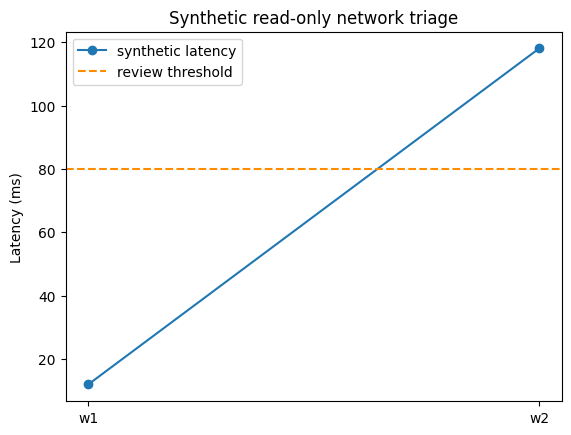

In [6]:
import matplotlib.pyplot as plt
plt.plot([r["window"] for r in telemetry], [r["latency_ms"] for r in telemetry], marker="o", label="synthetic latency")
plt.axhline(80, color="darkorange", linestyle="--", label="review threshold")
plt.ylabel("Latency (ms)")
plt.title("Synthetic read-only network triage")
plt.legend()
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
malformed = {"window": "bad", "latency_ms": 90.0}
try:
    triage(malformed)
except ValueError as error:
    print("Rejected malformed telemetry:", error)
print("Valid record:", triage(telemetry[1]))

Rejected malformed telemetry: telemetry row is missing required fields
Valid record: {'window': 'w2', 'review': True, 'evidence': ['high latency', 'packet loss']}


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

1. Add a synthetic error-counter field. 2. Explain how maintenance can trigger a false alert. 3. Propose a time split, missed-incident metric, and alert-burden measure.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

Synthetic analytics can teach pipeline design but cannot validate operational quality. Explain which evidence an operator should see and why device writes are out of scope.

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.